# Lucas-Kanade en un solo punto

La idea del paper en corto:

- $F$ es la imagen nueva y $G$ la anterior. Buscamos el desplazamiento $h$ que cumple $G(x) = F(x + h)$.
- Si $h$ es pequeño: $F(x+h) \approx F(x) + h \, \partial F / \partial x$.
- Minimizando el error L2 en una ventana $R$ queda:

$$h = \left( \sum_{x \in R} \nabla F \, \nabla F^T \right)^{-1} \sum_{x \in R} \nabla F \,[G(x) - F(x)]$$

En 2D es un sistema de 2x2, $A\,h = b$, con cinco sumas:

$$A = \begin{pmatrix} \sum F_x^2 & \sum F_x F_y \\ \sum F_x F_y & \sum F_y^2 \end{pmatrix} \qquad b = \begin{pmatrix} \sum (G-F)F_x \\ \sum (G-F)F_y \end{pmatrix}$$

Pasos:
1. Leer dos frames y pasarlos a gris
2. Elegir el punto y la ventana
3. Ver cómo cambia el brillo entre los dos frames ($G - F$)
4. Calcular las derivadas $F_x$ y $F_y$
5. Ver las cinco sumas y construir la matriz $A$
6. Resolver y comprobar si el ajuste mejora
7. Dibujar la flecha

In [11]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

#### 1. Lectura de frames

Si el movimiento entre dos frames seguidos es muy pequeño se puede subir `SEPARACION`, y con `FRAME_INICIAL` se elige en qué momento del vídeo se mira.

In [12]:
RUTA_VIDEO = "new_york.mp4"     # (0 para la webcam)
FRAME_INICIAL = 0               # frame del vídeo donde empezamos
SEPARACION = 1                  # 1 = frames seguidos

cap = cv2.VideoCapture(RUTA_VIDEO)
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_INICIAL)

ok1, frame_ant = cap.read()          # frame anterior -> G
for _ in range(SEPARACION - 1):
    cap.read()                       # nos saltamos los frames del medio
ok2, frame_nue = cap.read()          # frame nuevo    -> F
cap.release()

if not (ok1 and ok2):
    print("No se han podido leer dos frames, revisa la ruta del vídeo")
else:
    print("Tamaño del frame:", frame_ant.shape)

Tamaño del frame: (720, 1280, 3)


#### Escala de grises y suavizado

La aproximación lineal solo vale si $h$ es pequeño, y suavizar la imagen ayuda a ampliar ese rango. Por eso pasamos a gris y aplicamos un desenfoque gaussiano suave.

In [13]:
def preparar(frame):
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    return gris.astype(np.float32)      # float para que las restas no den problemas

G = preparar(frame_ant)    # imagen anterior
F = preparar(frame_nue)    # imagen nueva

#### 2. Elegir el punto y la ventana

`X, Y` es el punto (columna, fila) y `R` el radio de la ventana, que será de $(2R+1) \times (2R+1)$ píxeles. Con `R = 3` la ventana es de 7x7 y se pueden leer los números en las figuras. Si se sube `R` las figuras siguen funcionando, pero ya no muestran los valores.

Los ejes de la imagen de la izquierda son coordenadas en píxeles, sirven para elegir el punto. Conviene escoger un sitio con textura (una esquina, un detalle), no una zona lisa como el cielo.

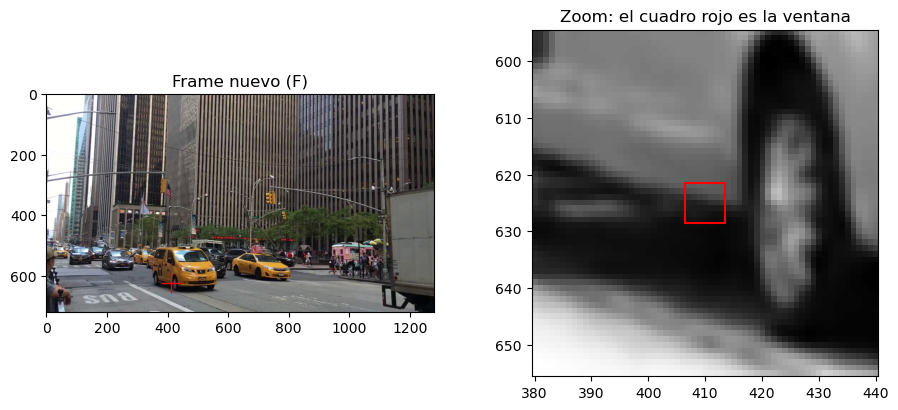

In [14]:
X, Y = 410, 625      # punto a analizar
R = 3                # radio de la ventana
tam = 2 * R + 1

alto, ancho = F.shape
if X - R < 0 or Y - R < 0 or X + R >= ancho or Y + R >= alto:
    print("El punto está demasiado cerca del borde para esta ventana")

Z = 30    # zoom: píxeles que se ven a cada lado del punto

def zoom(ax, imagen):
    x0, x1 = max(X - Z, 0), min(X + Z + 1, ancho)
    y0, y1 = max(Y - Z, 0), min(Y + Z + 1, alto)
    ax.imshow(imagen[y0:y1, x0:x1], cmap="gray",
              extent=(x0 - 0.5, x1 - 0.5, y1 - 0.5, y0 - 0.5))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

ax[0].imshow(cv2.cvtColor(frame_nue, cv2.COLOR_BGR2RGB))
ax[0].plot(X, Y, "r+", markersize=14)
ax[0].set_title("Frame nuevo (F)")

zoom(ax[1], F)
ax[1].add_patch(plt.Rectangle((X - R - 0.5, Y - R - 0.5), tam, tam,
                              fill=False, edgecolor="red", linewidth=1.5))
ax[1].set_title("Zoom: el cuadro rojo es la ventana")
plt.show()

#### 3. Cómo cambia el brillo

Recortamos la ventana en $G$ y en $F$ y las restamos. Esa diferencia $G - F$ es lo que Lucas-Kanade intenta explicar con un desplazamiento. En azul y rojo se ve dónde el brillo ha bajado o subido, y si todo es casi blanco el brillo apenas ha cambiado (poco movimiento en ese punto).

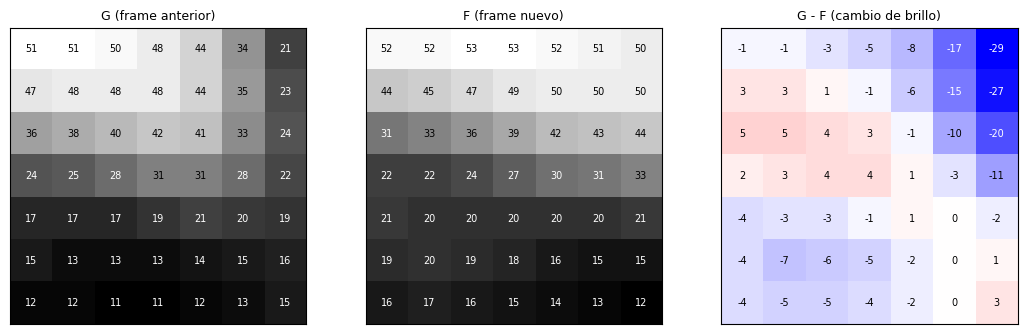

Suma de (G-F)^2 en la ventana: 3258.0


In [15]:
def mostrar(ax, M, titulo, cmap="gray", centrar=False):
    # dibuja una matriz pequeña y escribe los números encima si cabe
    if centrar:
        v = np.abs(M).max()
        if v == 0:
            v = 1
        im = ax.imshow(M, cmap=cmap, vmin=-v, vmax=v)
    else:
        im = ax.imshow(M, cmap=cmap)
    ax.set_title(titulo, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    if M.shape[0] <= 9:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                n = im.norm(M[i, j])
                if centrar:
                    color = "white" if (n < 0.25 or n > 0.75) else "black"
                else:
                    color = "white" if n < 0.5 else "black"
                ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center",
                        fontsize=7, color=color)

# ventanas alrededor del punto
wg = G[Y-R:Y+R+1, X-R:X+R+1]
wf = F[Y-R:Y+R+1, X-R:X+R+1]
wd = wg - wf                    # G - F

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
mostrar(ax[0], wg, "G (frame anterior)")
mostrar(ax[1], wf, "F (frame nuevo)")
mostrar(ax[2], wd, "G - F (cambio de brillo)", cmap="bwr", centrar=True)
plt.show()

print("Suma de (G-F)^2 en la ventana:", round(float(np.sum(wd ** 2)), 1))

#### 4. Derivadas

Se estima la derivada con una diferencia entre píxeles vecinos, con $\Delta x$ de un píxel:

$$F'(x) \approx \frac{F(x+\Delta x) - F(x)}{\Delta x}$$

La hacemos en x y en y sobre la imagen nueva $F$. Una $F_x$ grande significa que el brillo cambia mucho al movernos en horizontal en ese sitio (un borde vertical), y lo mismo con $F_y$ y los bordes horizontales.

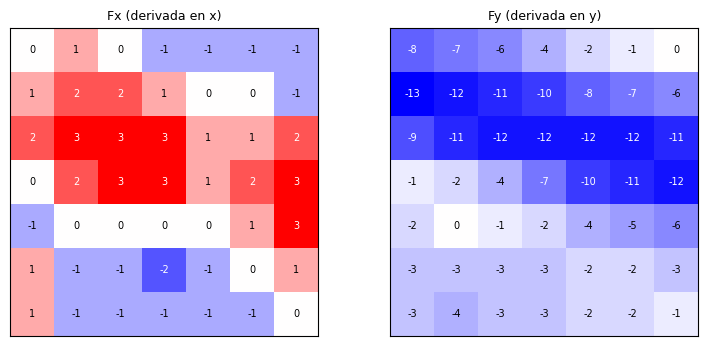

In [16]:
def derivadas(F):
    Fx = np.zeros_like(F)
    Fy = np.zeros_like(F)
    Fx[:, :-1] = F[:, 1:] - F[:, :-1]      # derivada en x (columna siguiente - actual)
    Fy[:-1, :] = F[1:, :] - F[:-1, :]      # derivada en y (fila siguiente - actual)
    return Fx, Fy

Fx, Fy = derivadas(F)

wx = Fx[Y-R:Y+R+1, X-R:X+R+1]
wy = Fy[Y-R:Y+R+1, X-R:X+R+1]

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
mostrar(ax[0], wx, "Fx (derivada en x)", cmap="bwr", centrar=True)
mostrar(ax[1], wy, "Fy (derivada en y)", cmap="bwr", centrar=True)
plt.show()

#### 5. Las cinco sumas y la matriz A

En cada píxel de la ventana se calculan estos cinco productos y luego se suman. Cada recuadro es uno de ellos, y la suma (el número que va en la matriz) aparece en el título.

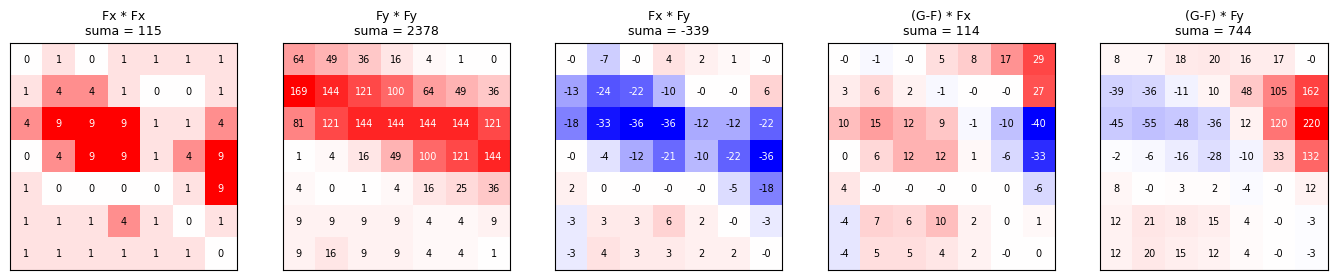

Matriz A =
[[ 115. -339.]
 [-339. 2378.]]

Vector b = [114. 744.]

det(A) = 158549.0
autovalores de A = [  65.3 2427.7]


In [17]:
productos = [
    ("Fx * Fx",       wx * wx),
    ("Fy * Fy",       wy * wy),
    ("Fx * Fy",       wx * wy),
    ("(G-F) * Fx",    wd * wx),
    ("(G-F) * Fy",    wd * wy),
]

fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for a, (nombre, M) in zip(ax, productos):
    mostrar(a, M, f"{nombre}\nsuma = {M.sum():.0f}", cmap="bwr", centrar=True)
plt.show()

# las cinco sumas
sxx = np.sum(wx * wx)
syy = np.sum(wy * wy)
sxy = np.sum(wx * wy)
sxd = np.sum(wd * wx)
syd = np.sum(wd * wy)

A = np.array([[sxx, sxy],
              [sxy, syy]])
b = np.array([sxd, syd])

np.set_printoptions(precision=1, suppress=True)
print("Matriz A =")
print(A)
print()
print("Vector b =", b)
print()
print("det(A) =", round(float(np.linalg.det(A)), 1))
print("autovalores de A =", np.linalg.eigvalsh(A))

Los autovalores de $A$ dicen si el punto sirve:

- **Los dos grandes:** hay textura en las dos direcciones (una esquina). Se puede resolver bien.
- **Uno grande y otro casi 0:** solo hay un borde. Solo se puede saber el movimiento perpendicular al borde, y el otro componente de $h$ sale poco fiable (es el problema de la apertura).
- **Los dos casi 0:** zona lisa, no hay información y $A$ no se puede invertir.

#### 6. Resolver y comprobar

Resolvemos el sistema $A\,h = b$. Para comprobar si el resultado tiene sentido, usamos la aproximación lineal del paper: si $h$ es bueno, $F + h \cdot \nabla F$ tiene que parecerse a $G$, y el error que queda tiene que ser menor que el de $G - F$.

In [18]:
if np.linalg.det(A) < 1e-6:
    h = None
    print("A no se puede invertir en este punto, prueba con otro (X, Y)")
else:
    h = np.linalg.solve(A, b)      # h = A^-1 b
    print("h = (hx, hy) =", np.round(h, 3), "píxeles")

h = (hx, hy) = [3.3 0.8] píxeles


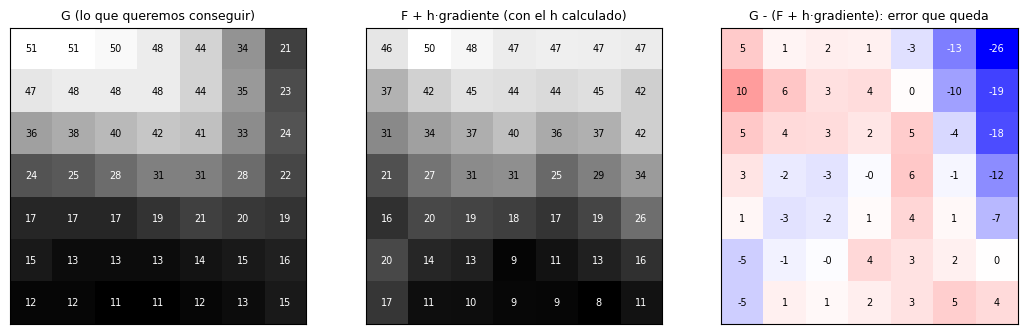

Error al cuadrado antes (G - F):           3258.0
Error al cuadrado después (con el h hallado): 2298.9


In [19]:
assert h is not None, "Con este punto A no se puede invertir, elige otro (X, Y)"

hx, hy = h
pred = wf + hx * wx + hy * wy      # F(x+h) ≈ F(x) + h·gradiente de F
res = wg - pred                    # error que queda

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
mostrar(ax[0], wg, "G (lo que queremos conseguir)")
mostrar(ax[1], pred, "F + h·gradiente (con el h calculado)")
mostrar(ax[2], res, "G - (F + h·gradiente): error que queda", cmap="bwr", centrar=True)
plt.show()

print("Error al cuadrado antes (G - F):          ", round(float(np.sum(wd ** 2)), 1))
print("Error al cuadrado después (con el h hallado):", round(float(np.sum(res ** 2)), 1))

#### 7. La flecha

Se dibuja $h$ sobre el zoom, empezando en el punto. Se multiplica por `ESCALA` para que se vea, porque entre dos frames el desplazamiento suele ser de un píxel o menos.

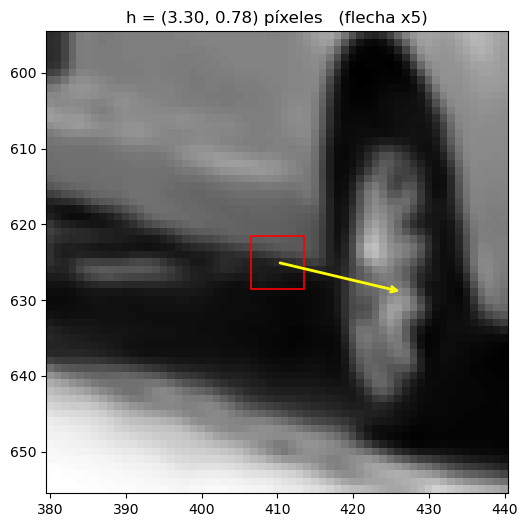

In [20]:
ESCALA = 5

fig, ax = plt.subplots(figsize=(6, 6))
zoom(ax, F)
ax.add_patch(plt.Rectangle((X - R - 0.5, Y - R - 0.5), tam, tam,
                           fill=False, edgecolor="red", linewidth=1.2))
ax.annotate("", xy=(X + ESCALA * hx, Y + ESCALA * hy), xytext=(X, Y),
            arrowprops=dict(arrowstyle="->", color="yellow", lw=2))
ax.set_title(f"h = ({hx:.2f}, {hy:.2f}) píxeles   (flecha x{ESCALA})")
plt.show()